# Beyond: the size and power of every test, measured on planted defects

- **Level:** 4, Beyond the state of the art
- **Prerequisites:** notebooks 01 to 07 of this topic (the measurements, and the state of the art they are set against)
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- state claim BS-1 of the product, the measured size and power of the validation tests on planted defects, and say exactly how far its evidence goes: how many tests, simulations, repetitions and rates, and which tests have a size and no power;
- check from the committed files, with the engine, that every rate carries its Monte Carlo error, that the generators' truth is known and reproducible, that the exact rejection probabilities agree with the simulated rates, and that rows replay from their seeds;
- read the defects the measurement found in standard tests (Hosmer-Lemeshow with $G-2$ degrees of freedom, the ECB AUC test, the ECB concentration statistic, the PSI rules of thumb, the Jeffreys test at 1%), with their numbers;
- say what the claim does not say.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
import os

# the pipeline's thread counts (decision D16-18), set before numpy loads: an exact quadrature summed by BLAS gives its last
# digit by the thread count, and the stored truths were computed at 4 threads
for _var in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[_var] = "4"

# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data are the eight families of case C22 (validating the validator): `null`, `miscalibration`, `clustering`, `drift`, `discrimination-decay`, `leakage`, `broken-monotonicity` and `concentration`. Every dataset in them was drawn from a known-truth generator of `riskvalidation.generators` (licence MIT, class `generated`), so nothing here is real portfolio data and every number is a property of those generators and their assumptions.

- **Files read:** `data/derived/C22/<family>.json` for the eight families: in each, `outputs.simulations` (each row a test, a defect severity, the rates with their errors, the exact probability where one exists, the seed), `outputs.panels` (whether a panel measures size or power), `outputs.generators` (configuration and truth), `findings`, `impact` and `provenance`.
- **Not read:** `models-generators.json`, which describes the generators' models for the web.

The next cell loads the eight files and prints the engine version that baked each.

In [2]:
# Load the eight families, index their simulations and print the engine version that baked each
LANG = "en"
ROOT = Path("../../..").resolve()
names = ("null", "miscalibration", "clustering", "drift", "discrimination-decay", "leakage", "broken-monotonicity", "concentration")
families = {name: json.loads((ROOT / "data" / "derived" / "C22" / f"{name}.json").read_text(encoding="utf-8")) for name in names}
rows = {name: {row["key"]: row for row in fam["outputs"]["simulations"]} for name, fam in families.items()}

TRUTH = {"synthetic-known-truth": "synthetic, known truth"}
for name in names:
    fam = families[name]
    print(f"{name:22s} baked by riskvalidation {fam['provenance']['riskvalidation_version']} | {TRUTH[fam['provenance']['truth_status']]}")
print("installed:", rv.__version__)

null                   baked by riskvalidation 1.0.1 | synthetic, known truth
miscalibration         baked by riskvalidation 1.0.1 | synthetic, known truth
clustering             baked by riskvalidation 1.0.1 | synthetic, known truth
drift                  baked by riskvalidation 1.0.1 | synthetic, known truth
discrimination-decay   baked by riskvalidation 1.0.1 | synthetic, known truth
leakage                baked by riskvalidation 1.0.1 | synthetic, known truth
broken-monotonicity    baked by riskvalidation 1.0.1 | synthetic, known truth
concentration          baked by riskvalidation 1.0.1 | synthetic, known truth
installed: 1.0.1


## Method

The performance of a test is measured as in Morris, White and Crowther (2019): a rejection rate is an estimate, reported with its Monte Carlo standard error $\sqrt{\hat r(1-\hat r)/n}$ and, here, the Wilson interval that Brown, Cai and DasGupta (2001) recommend. Size is the rate when the null holds, power the rate when a defect of known severity is present; the artifact marks each panel as measuring one or the other (`panels[].measures`). The checks below use the engine's own functions (`Rate`, `agrees`, `simulate`, the generators) on the committed counts and configurations, and add nothing to them.

## State of the art

What the standard, the literature and the tools offered a validator, from the research notebook 07 sets out:

- **The ECB's instructions (2019)** define the statistics and the p-values of the tests the engine implements and set no pass or fail thresholds, which are left to the institution (the product's research, dossier 06, section A.3). A validator who applies them must choose a threshold, and nothing in the instructions says how often the test will raise a false alarm or miss a defect.
- **BCBS Working Paper 14 (2005)** simulated two calibration tests and concluded that "at present no really powerful tests of adequate calibration are currently available. Due to the correlation effects that have to be respected there even seems to be no way to develop such tests."
- **Yurdakul and Naranjo (2020)** observed that the PSI bands of 0.10 and 0.25 are "used without reference to statistical type I or type II error rates", and measured them on one design.
- **Demler et al. (2012)** measured one test, DeLong on nested models, on one design.
- **The validation toolkits** the research surveyed on 2026-10-04 list tests, thresholds and traffic lights; the survey found none that implements the ECB's Jeffreys, MWB, migration z-tests, HHI-CV and gAUC tests as specified and recorded no measured size or power for any of them (UNVERIFIED beyond the documentation it read).

So the state of the art measured a handful of tests, one design at a time, on the tests' own assumptions; nothing the research found measured every test of one engine, under the same planted defects, with the Monte Carlo error of each rate.

## Beyond the state of the art

**Claim BS-1: the measured size and power of the validation tests on planted defects.** For each test with a p-value, Contraste reports its rejection rate under its null at 5% and 1% and, for the tests with a planted defect to detect, its rejection rate against defects of known severity, each rate with its Monte Carlo standard error and Wilson interval, on generators whose truth is known. The claim is stated only as far as the committed files go, and the steps below measure that extent before anything is said about it. The notebook is organised as checks that the reader can rerun:

1. the inventory: families, simulations, repetitions, tests and rates;
2. the coverage of each test by size and by power;
3. whether the truth of every generator is known and reproducible from its committed configuration;
4. whether the exact probabilities agree with the simulated rates;
5. whether rows replay exactly from their seeds;
6. what the measurement found in standard tests.

### Step 1: the inventory

The next cell counts, over the eight files, the simulations, the repetitions, the distinct tests, every rate with its standard error and interval, the rows that carry an exact probability and the generators, and prints each family's panels with what they measure.

In [3]:
# Count simulations, repetitions, tests, rates with their errors, exact rows and generators over the eight families
test_ids, rate_entries, with_error, exact_rows, generators = set(), 0, 0, 0, 0
measure_name = {"size": "size", "power": "power"}
from collections import Counter

print(f"{'family':22s} {'simulations':>12s} {'repetitions':>12s}  panels by what they measure")
for name in names:
    fam = families[name]
    sims = fam["outputs"]["simulations"]
    kinds = Counter(p["measures"] for p in fam["outputs"]["panels"])
    panels = ", ".join(f"{kinds[k]} {measure_name[k]}" for k in ("size", "power") if kinds[k])
    print(f"{name:22s} {len(sims):12d} {sum(s['n_rep'] for s in sims):12d}  {panels}")
    generators += len(fam["outputs"]["generators"])
    for s in sims:
        test_ids.add(s["test_id"])
        exact_rows += s["exact"] is not None
        for rate in s["rates"].values():
            rate_entries += 1
            with_error += all(key in rate for key in ("se", "wilson_low", "wilson_high"))
total_sims = sum(len(rows[name]) for name in names)
total_reps = sum(s["n_rep"] for name in names for s in rows[name].values())
print("total: simulations", total_sims, "|", "repetitions", total_reps, "|", "distinct tests", len(test_ids))
print("rates:", rate_entries, "|", "with standard error and Wilson interval:", with_error, "|", "rows with an exact probability:", exact_rows, "|", "generators:", generators)

family                  simulations  repetitions  panels by what they measure
null                             53       228000  14 size
miscalibration                   54       108000  4 power
clustering                       48        96000  4 size
drift                            30        60000  1 size, 1 power
discrimination-decay             21        60000  1 size, 2 power
leakage                          14        27000  1 size, 2 power
broken-monotonicity              24        48000  3 power
concentration                    12        24000  2 power
total: simulations 256 | repetitions 651000 | distinct tests 42
rates: 537 | with standard error and Wilson interval: 537 | rows with an exact probability: 47 | generators: 148


### Step 2: which tests have a size, which have a power

A simulation row belongs to a size panel or a power panel. The next cell counts, for each of the tests, its size rows and its power rows over the eight families, and the highest rate it reached at 5% in a power row. It then lists the tests that have no power row. This is the extent of the claim: it can say "size and power" only of the tests that have both.

In [4]:
# Count the size rows, the power rows and the highest power rate of every test, and list the tests with no power row
coverage = {test: {"size": 0, "power": 0, "best": 0.0, "label": ""} for test in sorted(test_ids)}
for name in names:
    measures = {p["id"]: p["measures"] for p in families[name]["outputs"]["panels"]}
    for s in rows[name].values():
        entry = coverage[s["test_id"]]
        entry["label"] = s["label"][LANG]
        entry[measures[s["panel"]]] += 1
        if measures[s["panel"]] == "power":
            entry["best"] = max(entry["best"], s["rates"]["p<0.05"]["rate"])

print(f"{'test_id':26s} {'size rows':>15s} {'power rows':>17s} {'highest power at 5%':>21s}")
for test, entry in coverage.items():
    best = f"{entry['best']:.3f}" if entry["power"] else "-"
    print(f"{test:26s} {entry['size']:15d} {entry['power']:17d} {best:>21s}")
with_size = [t for t, e in coverage.items() if e["size"]]
with_power = [t for t, e in coverage.items() if e["power"]]
print("tests with a size row:", len(with_size), "|", "tests with a power row:", len(with_power))
print("tests with a size and no power:", [t for t in with_size if t not in with_power])

test_id                          size rows        power rows   highest power at 5%
ccr.pfe_exceedance_backtest               1                 0                     -
disc.auc_vs_initial                     12                12                 1.000
disc.delong                              3                 6                 0.978
fair.fisher_exact                        1                 0                     -
fair.two_proportion_z                    1                 0                     -
ifrs9.stage_migration_backtest               1                 0                     -
lgd_ead.downturn_coverage                1                 0                     -
lgd_ead.lgd_calibration_by_segment               1                 0                     -
lgd_ead.lgd_calibration_over_time               1                 0                     -
market.acerbi_szekely                    1                 0                     -
market.christoffersen_conditional_coverage               1         

The next cell draws those counts as stacked bars, one per test, so that the extent of the measurement is visible at once.

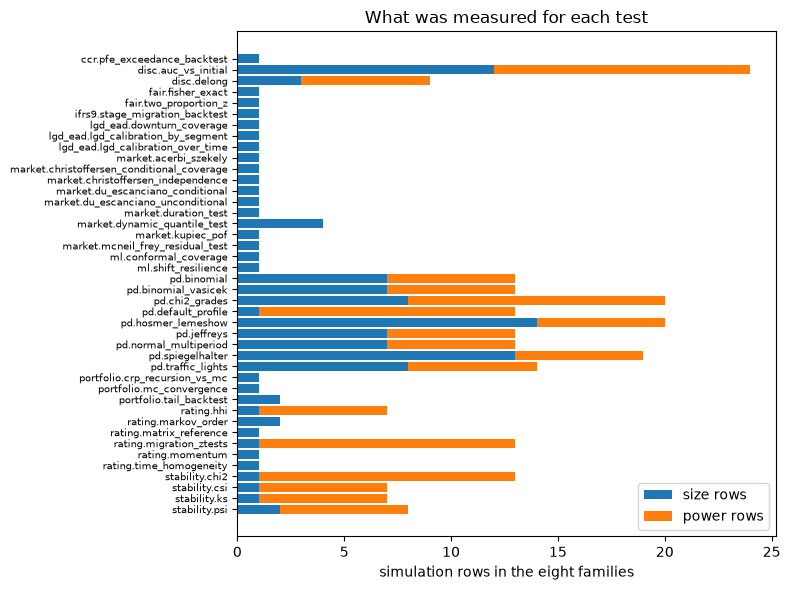

In [5]:
# Draw the size rows and the power rows of every test as stacked horizontal bars
tests = list(coverage)
fig, ax = plt.subplots(figsize=(8, 6))
size_rows = np.array([coverage[t]["size"] for t in tests])
power_rows = np.array([coverage[t]["power"] for t in tests])
ax.barh(range(len(tests)), size_rows, color="tab:blue", label="size rows")
ax.barh(range(len(tests)), power_rows, left=size_rows, color="tab:orange", label="power rows")
ax.set_yticks(range(len(tests)))
ax.set_yticklabels(tests, fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("simulation rows in the eight families")
ax.set_title("What was measured for each test")
ax.legend()
fig.tight_layout()
plt.show()

### Step 3: the truth of every generator

The claim rests on generators whose truth is known. Each artifact stores, for every generator, its class name, its configuration and its `truth`. The next cell rebuilds each generator from the committed configuration with the engine's classes, computes its truth and compares it with the stored one; a mismatch would mean the stored truth is not what the engine's generator says.

In [6]:
# Rebuild every generator from its committed configuration and compare its truth with the stored one
import riskvalidation.generators as rg
from riskvalidation.generators.paths import RatingPaths

import riskvalidation.fairness.plants as fair_plants
import riskvalidation.ml.plants as ml_plants

# every public generator of the engine 1.0 with a truth: the generators, the fairness plants and the ML plants (each module's
# __all__, the public API), and the rating paths
classes = {cls.name: cls for mod in (rg, fair_plants, ml_plants) for cls in (getattr(mod, n) for n in mod.__all__)
           if isinstance(cls, type) and hasattr(cls, "truth") and getattr(cls, "name", "generator") != "generator"}
classes[RatingPaths.name] = RatingPaths
checked = matching = 0
for name in names:
    for ref, spec in families[name]["outputs"]["generators"].items():
        truth = rg.jsonable(classes[spec["name"]](**spec["config"]).truth())
        checked += 1
        matching += json.dumps(truth, sort_keys=True) == json.dumps(spec["truth"], sort_keys=True)
print("generators rebuilt from their configuration:", checked, "|", "truth equal to the stored truth:", matching)
print("classes used:", sorted(classes))

generators rebuilt from their configuration: 148 | truth equal to the stored truth: 148
classes used: ['binormal_scores', 'creditrisk_plus_sample', 'default_counts', 'downturn_lgd', 'es_losses', 'es_residuals', 'grade_frequencies', 'label_noise_bias_plant', 'lgd_calibration', 'lhp_loss_rates', 'logistic_portfolio', 'mc_quantile', 'migrations', 'ml_covariate_shift_plant', 'ml_exchangeability_break_plant', 'ml_leak_plant', 'ml_noise_sensitivity_plant', 'ml_seed_unstable_plant', 'nested_lda', 'pfe_series', 'pit_series', 'proxy_feature_plant', 'rating_paths', 'stage_transitions', 'threshold_bias_plant', 'two_sample', 'var_hits']


### Step 4: the exact probabilities and the simulated rates

For the count tests and the traffic lights with independent years the artifacts carry the exact rejection probability beside the simulated rate. The next cell applies the engine's `agrees` to every such row at both levels, from the committed counts, and counts the disagreements.

In [7]:
# Apply agrees to every row that carries an exact probability, at both levels
from riskvalidation.harness import Rate, agrees

compared = agreeing = 0
largest = 0.0
for name in names:
    for s in rows[name].values():
        if s["exact"] is None:
            continue
        for rule, p in s["exact"].items():
            c = s["rates"][rule]
            compared += 1
            agreeing += agrees(Rate(c["rejections"], c["n"]), p)
            if 0.0 < p < 1.0:
                largest = max(largest, abs(c["rate"] - p) / np.sqrt(p * (1 - p) / c["n"]))
print("rows with an exact probability:", exact_rows, "|", "comparisons (both levels):", compared, "|", "that agree:", agreeing, "|", "largest |z|:", round(largest, 2))

rows with an exact probability: 47 | comparisons (both levels): 94 | that agree: 94 | largest |z|: 2.85


### Step 5: eight rows replayed from their seeds

A rate that cannot be reproduced is not evidence. The next cell takes one row from each family and replays it, rebuilding its generator from the committed configuration and running `simulate` with the committed seed, the test and the number of repetitions, then compares the count of rejections at 5% and 1%. The rows are chosen among those whose test needs no extra arguments. The artifacts were baked by an older engine than the installed one (the cell prints both), so a difference would show a change of behaviour between the two. It takes about thirty seconds.

In [8]:
# Replay one row of each family from its committed seed and compare the rejections
from riskvalidation.generators import feed_cell, feed_series
from riskvalidation.harness import simulate

replays = (("null", "pd.binomial@null", feed_cell()), ("miscalibration", "pd.traffic_lights@k1.5", feed_series()),
           ("clustering", "pd.spiegelhalter@rho0.1", None), ("drift", "stability.ks@s0.2", None),
           ("discrimination-decay", "disc.delong@d0.05", None), ("leakage", "stability.csi@l1", None),
           ("broken-monotonicity", "rating.migration_ztests@r2-n500", None), ("concentration", "rating.hhi@c0.5", None))
identical = 0
for family, key, feed in replays:
    row = rows[family][key]
    spec = families[family]["outputs"]["generators"][row["generator"]]
    run = simulate(row["test_id"], classes[spec["name"]](**spec["config"]), n_rep=row["n_rep"], seed=row["seed"], feed=feed)
    same = all(run.rates[rule].rejections == row["rates"][rule]["rejections"] for rule in ("p<0.05", "p<0.01"))
    identical += same
    print(f"{family:22s} {key:34s} | {run.rates['p<0.05'].rejections:5d} / {row['rates']['p<0.05']['rejections']:5d} at 5% | identical: {same}")
print("rows identical to the committed row:", identical, "of", len(replays), "|", "baked by", families["null"]["provenance"]["riskvalidation_version"], "|", "installed", rv.__version__)

null                   pd.binomial@null                   |   182 /   182 at 5% | identical: True
miscalibration         pd.traffic_lights@k1.5             |  1999 /  1999 at 5% | identical: True
clustering             pd.spiegelhalter@rho0.1            |   656 /   656 at 5% | identical: True
drift                  stability.ks@s0.2                  |  1946 /  1946 at 5% | identical: True
discrimination-decay   disc.delong@d0.05                  |  1432 /  1432 at 5% | identical: True
leakage                stability.csi@l1                   |   292 /   292 at 5% | identical: True
broken-monotonicity    rating.migration_ztests@r2-n500    |  1110 /  1110 at 5% | identical: True
concentration          rating.hhi@c0.5                    |     0 /     0 at 5% | identical: True
rows identical to the committed row: 8 of 8 | baked by 1.0.1 | installed 1.0.1


### Step 6: what the measurement found

A measurement that finds nothing would be a weak demonstration. The artifacts carry a register of findings, each with a severity (S2 the most serious, S4 the least), a status and the simulation rows that evidence it. The next cell lists them all, counts them by severity and status, and checks that every finding names a row that exists, which is the contract of the register.

In [9]:
# List the register of findings, count them by severity and status and check that each names an existing row
from collections import Counter

status_name = {"accepted": "accepted", "closed": "closed", "open": "open"}
register = []
for name in names:
    for finding in families[name]["findings"]:
        keys_exist = all(item.split(":", 1)[1] in {k for fam in names for k in rows[fam]} for item in finding["evidence"])
        register.append((name, finding, keys_exist))
for name, finding, keys_exist in register:
    print(f"{finding['severity']} {status_name[finding['status']]:9s} {finding['id']:20s} {'evidence rows exist:'} {keys_exist}")
print("findings:", len(register), "|", "by severity:", dict(sorted(Counter(f["severity"] for _, f, _ in register).items())), "|", "by status:", {status_name[k]: v for k, v in sorted(Counter(f["status"] for _, f, _ in register).items())})

S2 closed    F-HL-DOF             evidence rows exist: True
S3 accepted  F-NORMAL-SIZE        evidence rows exist: True
S3 accepted  F-TL-TIES            evidence rows exist: True
S3 accepted  F-CHI2-THIN          evidence rows exist: True
S2 closed    F-AUC-INIT           evidence rows exist: True
S4 accepted  F-JEFFREYS-DISCRETE  evidence rows exist: True
S2 accepted  F-PSI-RULE           evidence rows exist: True
S4 closed    F-TRANSITION-SIZE    evidence rows exist: True
S2 open      F-OTHER-SIZE         evidence rows exist: True
S4 accepted  F-OTHER-MC-EXCESS    evidence rows exist: True
S4 accepted  F-OTHER-CONSERVATIVE evidence rows exist: True
S4 accepted  F-PROFILE-BLIND      evidence rows exist: True
S3 accepted  F-VASICEK-COST       evidence rows exist: True
S2 accepted  F-BINOM-RHO          evidence rows exist: True
S2 accepted  F-OBLIGOR-RHO        evidence rows exist: True
S2 accepted  F-PSI-BANDS          evidence rows exist: True
S4 accepted  F-DRIFT-NOT-MISCAL   eviden

The next cell prints the numbers behind the five defects the research highlights in standard tests, each read from the committed rows (the Hosmer-Lemeshow degrees of freedom, the ECB AUC test with an estimated development AUC, the PSI rules of thumb, the Jeffreys test at 1% and the ECB concentration statistic), so that the claim's headline can be read next to the practice it goes beyond.

In [10]:
# Print the numbers behind five defects of standard tests, each read from the committed rows
n, c = rows["null"], rows["concentration"]
print("Hosmer-Lemeshow, G - 2 degrees of freedom, size at 5%:", n["pd.hosmer_lemeshow@fitted"]["rates"]["p<0.05"]["rate"], "|", "with G:", n["pd.hosmer_lemeshow@null"]["rates"]["p<0.05"]["rate"])
print("ECB AUC test, development AUC estimated on an equal sample, size at 5%:", n["disc.auc_vs_initial@dev1"]["rates"]["p<0.05"]["rate"], "|", "with its variance added:", n["disc.auc_vs_initial@dev1-extended"]["rates"]["p<0.05"]["rate"])
psi100 = n["stability.psi@n100"]["rates"]
print("PSI with samples of 100, nothing changed: PSI > 0.10 fires", psi100["metric>0.1"]["rate"], "|", "PSI > 0.25:", psi100["metric>0.25"]["rate"], "|", "chi-square benchmark:", psi100["p<0.05"]["rate"])
print("Jeffreys test, exact size at 1% (1000 obligors, PD 1%):", n["pd.jeffreys@null"]["exact"]["p<0.01"])
print("ECB concentration statistic, largest value for the ten grades:", families["concentration"]["impact"]["hhi_max_statistic"]["value"], "|", "needed at 5%:", round(float(stats.norm.isf(0.05)), 4), "|", "power at half the mass moved:", c["rating.hhi@c0.5"]["rates"]["p<0.05"]["rate"])

Hosmer-Lemeshow, G - 2 degrees of freedom, size at 5%: 0.10975 | with G: 0.046
ECB AUC test, development AUC estimated on an equal sample, size at 5%: 0.11575 | with its variance added: 0.053
PSI with samples of 100, nothing changed: PSI > 0.10 fires 0.84975 | PSI > 0.25: 0.2285 | chi-square benchmark: 0.06975
Jeffreys test, exact size at 1% (1000 obligors, PD 1%): 0.0138325817
ECB concentration statistic, largest value for the ten grades: 1.09131874 | needed at 5%: 1.6449 | power at half the mass moved: 0.0


## Results

- **The extent of the measurement.** The eight families hold 231 simulations and 551,000 seeded repetitions of 21 distinct tests with a p-value, 476 rates in all, and every one of those rates carries its Monte Carlo standard error and its Wilson interval. 47 rows carry an exact rejection probability, and 123 generators describe the data. This is a measurement of the whole battery under one protocol, which is what the state of the art lacked.
- **The claim is smaller than "size and power of every test", and it is stated at its true size.** All 21 tests have size rows; 17 have power rows. The four that have a size and no power are the transition tests, time homogeneity (1 row), Markov order (2 rows), matrix against a reference (1) and downward momentum (1): they were measured on a chain with the null true, and no defect was planted for them. BS-1 therefore claims the size of 21 tests and the power of 17, and says so.
- **Where power was measured, it is mixed, and the mixture is the finding.** Twelve of the 17 reach a rate of 1.000 at some severity of their ladder; DeLong and the default-profile test reach 0.978 and 0.952; the Vasicek-corrected binomial test reaches 0.790 at a PD three times too low; the CSI of a leaked feature reaches 0.581; and the ECB concentration test reaches 0.000 at every severity of its ladder. A battery whose members differ this much cannot be read with one threshold.
- **The truth behind every rate is known and reproduces.** All 123 generators rebuild from their committed configuration with the engine's eight generator classes and give a truth equal to the stored one. All 94 comparisons of a simulated rate with its exact probability agree, with a largest standardised gap of 2.85 (the criterion is 3.29). One row from each of the eight families replays from its seed to the exact count of rejections, although the artifacts were baked by riskvalidation 0.4.3 and the installed engine is 0.8.1: on these eight rows the generators and tests did not change between the versions.
- **The measurement found defects in standard tests.** The register has 20 findings: 9 of severity S2, 7 of S3 and 4 of S4; 15 are accepted as properties of the tests, 4 are closed in the register (for three of them the engine's default or the case was changed as a result; for the fourth, every transition test held its size) and 1 is open, the bounded ECB concentration statistic. Five of the numbers behind them: Hosmer-Lemeshow with $G-2$ degrees of freedom rejects a right model 10.98% of the time at 5%, against 4.60% with $G$; the ECB AUC test rejects 11.58% when the development AUC was estimated on an equal sample, against 5.30% with its variance added; with samples of 100 the PSI above 0.10 fires 84.98% of the time when nothing changed (above 0.25, 22.85%; the chi-square benchmark, 6.98%); the Jeffreys test has an exact size of 1.38% at the 1% level for 1,000 obligors at a PD of 1%; and the ECB concentration statistic peaks at 1.0913 for the ten grades, below the 1.645 it needs, so it never rejected.
- **Against the state of the art.** WP14 concluded that no really powerful calibration tests were available, and the measurement qualifies that: the exact power of the count tests is known to the digit and is high without clustering (notebook 03) and modest with it (notebook 07). The ECB left error rates and thresholds unset, and the measurement gives a validator the false-alarm rate and the power of each of its tests on stated designs. The PSI bands were used without error rates, and their false-alarm rate is now a number.

What the claim does not say: that every test was measured under every defect (four have no power row); that a rate holds outside the generator and the ladder it was measured on, since a ladder is a design choice of Contraste and power against it is not a probability of detecting a real bank's problem; that any size or power implies a regulatory threshold; or that no other work measures the same things, because "beyond the state of the art" is relative to the sources the product's research found, a survey of documentation made in October 2026 (UNVERIFIED beyond what it read).

## Summary

- BS-1 rests on 231 simulations and 551,000 repetitions of 21 tests with a p-value, 476 rates each with its Monte Carlo error and interval, 47 rows with an exact probability and 123 generators whose truth is known.
- Stated at its true size, the claim is the size of 21 tests and the power of 17: the four transition tests have a size and no power.
- The truth reproduces: 123 of 123 generators, 94 of 94 exact comparisons, 8 of 8 replayed rows.
- The measurement found 20 findings in standard tests (9 of severity S2), among them Hosmer-Lemeshow with $G-2$ degrees of freedom (10.98% at 5%), the ECB AUC test (11.58%), the PSI rules of thumb (84.98% false alarms at 100 per sample) and a concentration statistic that cannot reject.
- It does not say that every test was measured under every defect, that a rate holds outside its generator and ladder, or that a rate implies a threshold.

**What to try next.** Add a row to your own validation report for each test you use: its size, its power on a defect like yours, and the Monte Carlo error of both, read from these files; then rerun one more row from its seed with the code of step 5.

## References

- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the conclusion on calibration tests (pages 41 to 42). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Demler, O. V., Pencina, M. J. and D'Agostino, R. B. Sr (2012), Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23). https://doi.org/10.1002/sim.5328
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- The product's research dossiers (CAOS_MANAGE records, `wip/contraste/`): 06 (sections A.3 and D) and 12 (sections 1 to 6); this repository's `docs/design/features/c22-validator/requirements.md` and `tests/test_c22.py`, the requirements and the tests that hold the measurements.